# Lab: Relationships Between Quantitative Features

Use a historical mammal sleep dataset to compare dreaming, non-dreaming, and total sleep. Use non-dreaming versus total sleep as the main model, then examine whether danger and predation ratings add information. Finally, investigate the nonlinear pattern between gestation time and total sleep.

Support conclusions with the plots and calculations. Explain how well a straight line follows the points and how much variation remains.

## Learning goals

- Describe whether points trend upward or downward, follow a straight or curved pattern, cluster closely around that pattern, or include unusual observations.
- Calculate correlation and interpret R-squared on the correct response scale.
- Recognize nonlinear patterns and compare original gestation with log-transformed gestation.
- Examine additional categorical features visually and compare model R-squared on the same observations.
- Check missing codes, units, category counts, and transformations.
- Distinguish improved fit to observed records from causation and performance on new data.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can answer it?
3. **Evidence:** What should we calculate and display?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete each investigation in order. Use separate cells for individual operations and add cells as needed. Give figures informative titles, named colors, and axis labels with units or transformations. Use the default point transparency and line widths. `ci=None` can omit confidence bands so the patterns and group lines are easier to compare.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code and checking every claim against the source and your output. Complete the AI-use reflection at the end.

## Dataset and context

Use the [StatLib mammal sleep data hosted by UC Berkeley](https://www.stat.berkeley.edu/~spector/s100/data/sleep.dat) and its [measurement dictionary](https://www.stat.berkeley.edu/~spector/s100/data/sleep.html). A local copy is supplied as `data/mammal_sleep.csv`.

The supplied `data/mammal_sleep.csv` contains all 62 records and 11 features, including species names and both sleep phases. One row describes a mammal species, not an individual animal or a night. The data trace to Allison and Cicchetti's 1976 study, [Sleep in mammals: ecological and constitutional correlates](https://pubmed.ncbi.nlm.nih.gov/982039/). This is a historical comparative dataset, not a random sample of all mammals; individual collection dates are not supplied.

Course preparation preserves all values and names, gives columns descriptive names, and converts the source's `-999` missing code into blank CSV fields. Use ordinary `pd.read_csv()`; blanks are recognized as missing. The terms dreaming and non-dreaming identify the study's sleep-phase measurements; they are not direct reports of an animal's subjective dream experiences.

### Data dictionary

| Feature | Meaning and units or codes |
| --- | --- |
| `species` | Species label as recorded in the historical source |
| `non_dreaming_sleep` | Non-dreaming sleep in hours per day |
| `dreaming_sleep` | Dreaming sleep in hours per day |
| `body_weight` | Body weight in kilograms |
| `brain_weight` | Brain weight in grams |
| `max_life_span` | Maximum lifespan in years |
| `gestation_time` | Gestation duration in days |
| `predation_index` | Ordered rating, 1–5: lower to higher likelihood of being preyed upon |
| `sleep_exposure_index` | Ordered rating, 1–5: more protected to more exposed sleeping conditions |
| `danger_index` | Ordered rating, 1–5: lower to higher overall danger from other animals |
| `total_sleep` | Total sleep in hours per day; sum of the two phases |

The indices are **ordinal categorical features**, even though stored as numbers. A one-point difference is not a documented equal increment of physical risk. Overall danger incorporates predation, sleep exposure, and other information, so these ratings are not independent measurements. In our models, represent rating levels as categories rather than assuming equal numerical spacing.

## Load and inspect the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
mammals_df = pd.read_csv("data/mammal_sleep.csv")

In [3]:
mammals_df.head()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
0,African elephant,6654.000,5712.0,NaN,NaN,3.3,38.6,645.0,3,5,3
1,African giant pouched rat,1.000,6.6,6.3,2.0,8.3,4.5,42.0,3,1,3
2,Arctic Fox,3.385,44.5,NaN,NaN,12.5,14.0,60.0,1,1,1
3,Arctic ground squirrel,0.920,5.7,NaN,NaN,16.5,NaN,25.0,5,2,3
4,Asian elephant,2547.000,4603.0,2.1,1.8,3.9,69.0,624.0,3,5,4


In [4]:
mammals_df.tail()

,species,body_weight,brain_weight,non_dreaming_sleep,dreaming_sleep,total_sleep,max_life_span,gestation_time,predation_index,sleep_exposure_index,danger_index
57,Tree hyrax,2.000,12.3,4.9,0.5,5.4,7.5,200.0,3,1,3
58,Tree shrew,0.104,2.5,13.2,2.6,15.8,2.3,46.0,3,2,2
59,Vervet,4.190,58.0,9.7,0.6,10.3,24.0,210.0,4,3,4
60,Water opossum,3.500,3.9,12.8,6.6,19.4,3.0,14.0,2,1,1
61,Yellow-bellied marmot,4.050,17.0,NaN,NaN,NaN,13.0,38.0,3,1,1


In [5]:
mammals_df.shape

(62, 11)

In [6]:
mammals_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   species               62 non-null     object 
 1   body_weight           62 non-null     float64
 2   brain_weight          62 non-null     float64
 3   non_dreaming_sleep    48 non-null     float64
 4   dreaming_sleep        50 non-null     float64
 5   total_sleep           58 non-null     float64
 6   max_life_span         58 non-null     float64
 7   gestation_time        58 non-null     float64
 8   predation_index       62 non-null     int64  
 9   sleep_exposure_index  62 non-null     int64  
 10  danger_index          62 non-null     int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 5.5+ KB


In [7]:
mammals_df.isnull().sum()

species                  0
body_weight              0
brain_weight             0
non_dreaming_sleep      14
dreaming_sleep          12
total_sleep              4
max_life_span            4
gestation_time           4
predation_index          0
sleep_exposure_index     0
danger_index             0
dtype: int64

**What does one row represent?**

Your answer: Each row represents one mammal species in the study

**Complete the table using the data dictionary, `.info()`, and `.isnull().sum()`. For data type, use categorical or quantitative. For data storage type, report the Pandas dtype. For missing values, report the count, including 0 when none are missing.**

| Feature | Data type | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `species` |  |  |  |
| `non_dreaming_sleep` |  |  |  |
| `dreaming_sleep` |  |  |  |
| `body_weight` |  |  |  |
| `brain_weight` |  |  |  |
| `max_life_span` |  |  |  |
| `gestation_time` |  |  |  |
| `predation_index` |  |  |  |
| `sleep_exposure_index` |  |  |  |
| `danger_index` |  |  |  |
| `total_sleep` |  |  |  |

Your answer:

# Investigation 1: Dreaming, non-dreaming, and total sleep

## Step 1: Question

**How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?**

Compare three relationships in hours per day: dreaming versus non-dreaming, dreaming versus total, and non-dreaming versus total. In the last comparison, use non-dreaming sleep on the horizontal axis and total sleep as the response. This is the main model for Investigation 2.

**Predict the direction and strength of each relationship. Which phase do you expect to be more strongly related to total sleep, and why?**

Your answer: I predict that dreaming and non-dreaming will have a weak positive relaationship. I think dreaming sleep and total sleep will be moderate positive relationship. Non-dreaming sleep and total sleep will have a strong positive. My guess is that non-dreaming sleep makes up more of the total so it will have the strongest relationship.

## Step 2: Data

Create `sleep_df` from records complete for `dreaming_sleep`, `non_dreaming_sleep`, `total_sleep`, `danger_index`, and `predation_index`. Use `.copy()` and keep `mammals_df` unchanged. Use this same subset in all three comparisons and in Investigation 2. How many records were removed from the dataset?

Check that sleep measurements are between 0 and 24 hours per day.

In [8]:
sleep_columns = ["dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
required_columns = sleep_columns + ["danger_index", "predation_index"]

sleep_df = mammals_df.dropna(subset=required_columns).copy()

print("Records kept:", len(sleep_df))
print("Records removed:", len(mammals_df) - len(sleep_df))

sleep_df[sleep_columns].agg(["min", "max"])

Records kept: 48
Records removed: 14


,dreaming_sleep,non_dreaming_sleep,total_sleep
min,0.0,2.1,2.9
max,6.6,17.9,19.9


## Step 3: Evidence

Create three labeled regression plots with `sns.regplot()`: non-dreaming sleep versus dreaming sleep, total sleep versus dreaming sleep, and total sleep versus non-dreaming sleep. In each description, the feature after “versus” goes on the horizontal axis. Calculate the correlation and simple-line R-squared for each pair. Describe the points before relying on the fitted line.

When describing a scatterplot:

- **Direction:** Do the points generally rise or fall from left to right?
- **Form:** Does the overall pattern look roughly straight, curved, or have no clear shape? This describes the arrangement of the points, not the line drawn by the plotting function.
- **Strength:** How closely do the points follow that pattern?
- **Unusual observations:** Which points are far from most of the others?

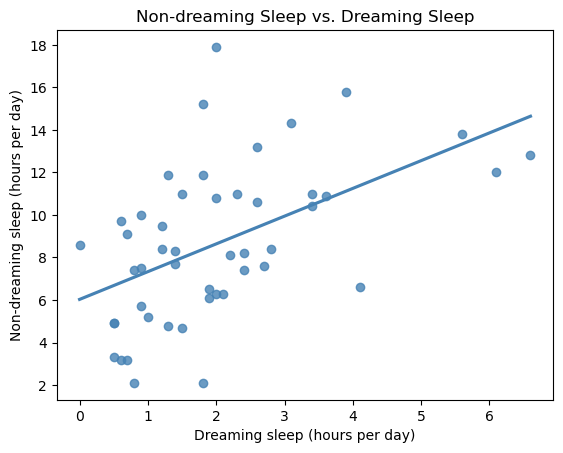

In [9]:
sns.regplot(
    data=sleep_df, x="dreaming_sleep", y="non_dreaming_sleep",
    color="steelblue", ci=None
)
plt.title("Non-dreaming Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Non-dreaming sleep (hours per day)")
plt.show()

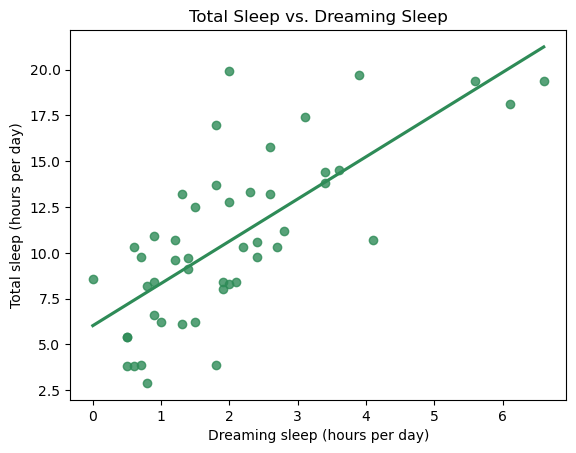

In [10]:
sns.regplot(
    data=sleep_df, x="dreaming_sleep", y="total_sleep",
    color="seagreen", ci=None
)
plt.title("Total Sleep vs. Dreaming Sleep")
plt.xlabel("Dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

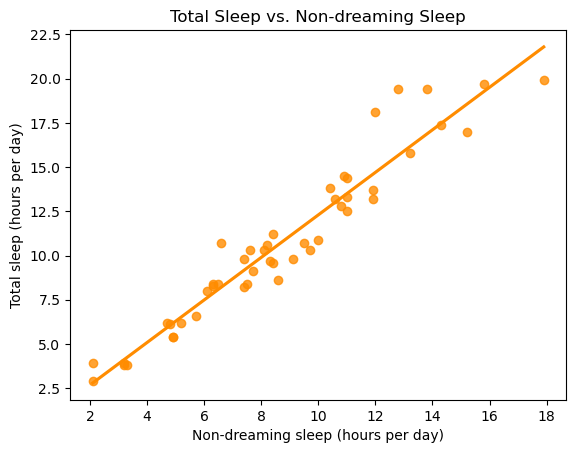

In [11]:
sns.regplot(
    data=sleep_df, x="non_dreaming_sleep", y="total_sleep",
    color="darkorange", ci=None
)
plt.title("Total Sleep vs. Non-dreaming Sleep")
plt.xlabel("Non-dreaming sleep (hours per day)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [12]:
pairs = [
    ("dreaming_sleep", "non_dreaming_sleep"),
    ("dreaming_sleep", "total_sleep"),
    ("non_dreaming_sleep", "total_sleep")
]

for x, y in pairs:
    r = sleep_df[x].corr(sleep_df[y])
    print(f"{y} vs. {x}: r = {r:.3f}, R-squared = {r**2:.3f}")

non_dreaming_sleep vs. dreaming_sleep: r = 0.514, R-squared = 0.264
total_sleep vs. dreaming_sleep: r = 0.727, R-squared = 0.529
total_sleep vs. non_dreaming_sleep: r = 0.963, R-squared = 0.927


**For each plot, do the points generally rise or fall? Is their pattern roughly straight or curved, and how closely do they follow it? Identify any unusual observations. Which plot is best summarized by a straight line? Explain what its R-squared tells you about total sleep.**

Your answer:All three plots rise from left to right. The first plot, non-dreaming vs. dreaming sleep, has a moderate positive trend. The pattern is roughly straight, but the points are spread out. One point stands out at about 2 hours of dreaming sleep and 18 hours of non-dreaming sleep.

The second plot, total sleep vs. dreaming sleep, also has a roughly straight upward trend.The points follow it more closely than in the first plot, but one species gets about 20 hours of total sleep with only 2 hours of dreaming sleep.

The third plot, total sleep vs. non-dreaming sleep, follows a straight line most closely (r = 0.963). One point around 13 hours of non-dreaming sleep and 19.5 hours of total sleep sits noticeably above the line. The model’s R^2 of 0.927 means it accounts for about 92.7% of the variation in total sleep across the 48 species, leaving about 7.3% unexplained by the line.

## Step 4: Check

Check that `dreaming_sleep + non_dreaming_sleep` agrees with `total_sleep` using `np.isclose()`, which allows for ordinary floating-point rounding. Display several original rows with their phase sum. Then display the three records with the longest non-dreaming sleep and locate their points on the non-dreaming versus total sleep plot. Do the plotted values agree with the records?

In [13]:
sleep_check = sleep_df[
    ["species", "dreaming_sleep", "non_dreaming_sleep", "total_sleep"]
].copy()

sleep_check["phase_sum"] = (
    sleep_check["dreaming_sleep"] + sleep_check["non_dreaming_sleep"]
)
sleep_check["matches_total"] = np.isclose(
    sleep_check["phase_sum"], sleep_check["total_sleep"]
)

print("Matching records:", sleep_check["matches_total"].sum(), "of", len(sleep_check))
sleep_check.head()

Matching records: 48 of 48


,species,dreaming_sleep,non_dreaming_sleep,total_sleep,phase_sum,matches_total
1,African giant pouched rat,2.0,6.3,8.3,8.3,True
4,Asian elephant,1.8,2.1,3.9,3.9,True
5,Baboon,0.7,9.1,9.8,9.8,True
6,Big brown bat,3.9,15.8,19.7,19.7,True
7,Brazilian tapir,1.0,5.2,6.2,6.2,True


In [14]:
sleep_check.nlargest(3, "non_dreaming_sleep")[
    ["species", "non_dreaming_sleep", "total_sleep"]
]

,species,non_dreaming_sleep,total_sleep
32,Little brown bat,17.9,19.9
6,Big brown bat,15.8,19.7
41,Owl monkey,15.2,17.0


## Step 5: Conclusion

**Research question:** How are dreaming and non-dreaming sleep related, and which phase has the stronger linear relationship with total sleep?

**Do mammals that spend more time in dreaming sleep also tend to spend more time in non-dreaming sleep? Which phase is more strongly related to total sleep? Support your answers with the plots, correlations, and R-squared values. Did the results match your prediction?**

Your answer: Mammals that spend more time in dreaming sleep tend to spend more time in non-dreaming sleep too. The points generally rose, but they were spread out. Non-dreaming sleep had the strongest relationship with total sleep. Its points followed the line more closely than the dreaming sleep plot.

## Step 6: Limitation

**State two limitations specific to these sleep relationships. Explain why a stronger correlation is not automatically a better scientific explanation.**

Your answer: First, total sleep includes non-dreaming sleep, so part of the strong correlation comes from comparing a part with its whole. The correlation describes how closely the values move together, while the biological reasons species sleep different amounts are still open. Second, I used 48 species with complete records from a historical dataset. The 14 excluded species might have different sleep patterns, so the results may change with a broader sample.

# Investigation 2: Do danger and predation add information?

## Step 1: Question

**Do danger and predation categories add information about total sleep beyond non-dreaming sleep?**

**Predict whether each index will add substantial, small, or little visible information. What would you look for at comparable non-dreaming-sleep durations?**

Your answer: I predict the danger index will add a small amount of information and the predation index will add little. Non-dreaming sleep already explains most of the variation in total sleep. I’ll look for whether species with similar hours of non-dreaming sleep have consistently higher or lower total sleep depending on their rating.

## Step 2: Data

Reuse `sleep_df` and its original sleep measurements. Count records for each danger and predation rating and display a cross-tabulation of the two indices. Keep all five original levels in their natural order. Higher predation index values mean a mammal is more likely to be preyed upon. Higher danger index values mean greater overall danger from other animals.

In [15]:
levels = [1, 2, 3, 4, 5]

danger_counts = sleep_df["danger_index"].value_counts().reindex(levels, fill_value=0)
predation_counts = sleep_df["predation_index"].value_counts().reindex(levels, fill_value=0)

pd.DataFrame({"Danger count": danger_counts, "Predation count": predation_counts})

,Danger count,Predation count
1,14,10
2,12,13
3,8,9
4,9,7
5,5,9


In [16]:
pd.crosstab(sleep_df["danger_index"], sleep_df["predation_index"]).reindex(
    index=levels, columns=levels, fill_value=0
)

predation_index,1,2,3,4,5
danger_index,,,,,
1,10,4,0,0,0
2,0,9,3,0,0
3,0,0,5,2,1
4,0,0,1,5,3
5,0,0,0,0,5


## Step 3: Evidence

Use `sns.lmplot()` twice on the non-dreaming–total sleep relationship, once colored by `danger_index` and once by `predation_index`. Set `hue_order=[1, 2, 3, 4, 5]`, use a named palette, and label the legend so the index direction is clear. The separate lines show group patterns; small groups may produce unstable lines. Compare groups where their non-dreaming-sleep ranges overlap.

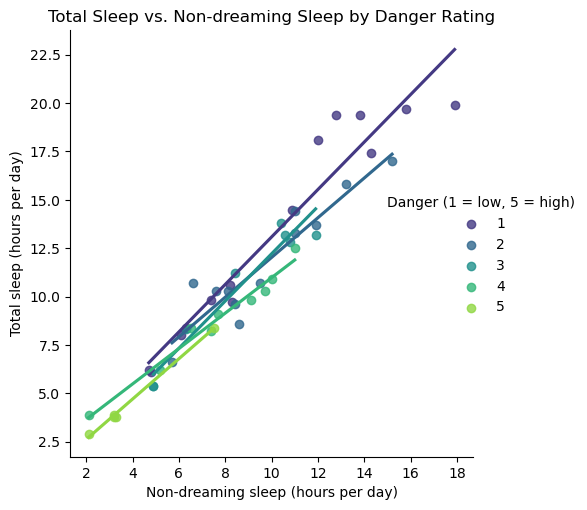

In [17]:
danger_plot = sns.lmplot(
    data=sleep_df, x="non_dreaming_sleep", y="total_sleep",
    hue="danger_index", hue_order=levels, palette="viridis", ci=None
)
danger_plot.set_axis_labels(
    "Non-dreaming sleep (hours per day)", "Total sleep (hours per day)"
)
danger_plot.ax.set_title("Total Sleep vs. Non-dreaming Sleep by Danger Rating")
danger_plot.legend.set_title("Danger (1 = low, 5 = high)")
plt.show()

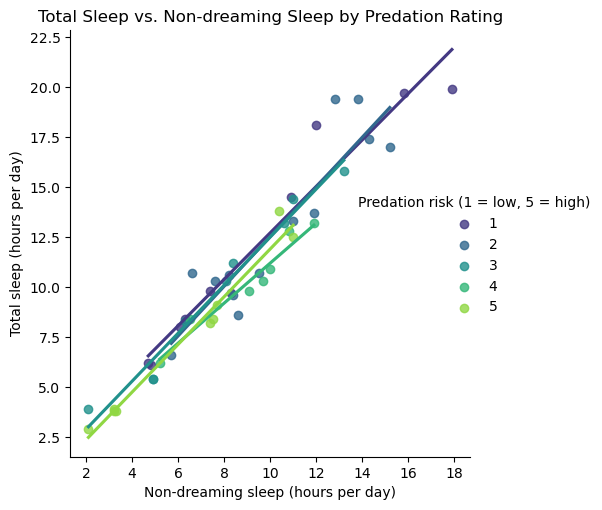

In [18]:
predation_plot = sns.lmplot(
    data=sleep_df, x="non_dreaming_sleep", y="total_sleep",
    hue="predation_index", hue_order=levels, palette="viridis", ci=None
)
predation_plot.set_axis_labels(
    "Non-dreaming sleep (hours per day)", "Total sleep (hours per day)"
)
predation_plot.ax.set_title("Total Sleep vs. Non-dreaming Sleep by Predation Rating")
predation_plot.legend.set_title("Predation risk (1 = low, 5 = high)")
plt.show()

**Describe overlap and separation in each plot. How do the group sizes and available non-dreaming-sleep ranges affect your interpretation?**

Your answer: In the danger plot, the groups overlap around 5–10 hours of non-dreaming sleep. The line for danger level 1 generally sits above level 4 where they overlap, especially around 8–11 hours. In the predation plot, the lines are closer together. Levels 1–3 overlap quite a bit, while levels 4 and 5 tend to sit a little lower in the middle of the plot. Some groups have fewer species or cover a shorter range, so a few points can have a big effect on their lines. I compared the groups where they had similar amounts of non-dreaming sleep.

### Compare model R-squared

The supplied helper follows the lecture's least-squares calculation. Read and run it; you do not need to recreate its matrix operations. `pd.get_dummies()` represents each rating with category indicators. `drop_first=True` chooses a reference level. This avoids assuming equal distances between index values.

These are **additive models**: one shared slope for the quantitative predictor and category-specific intercept adjustments. They differ from the separate group slopes in `lmplot()`. Compare the baseline, baseline plus danger, baseline plus predation, and baseline plus both, all on identical rows and the same response scale. Training R-squared cannot decrease when predictors are added to these nested models; an increase alone does not establish improved performance on new observations.

In [19]:
def calculate_r_squared(data, predictor, response, categorical_features):
    predictors = pd.get_dummies(
        data[[predictor, *categorical_features]],
        columns=categorical_features, drop_first=True, dtype=float
    )
    predictors.insert(0, "intercept", 1.0)
    x = predictors.to_numpy(dtype=float)
    y = data[response].to_numpy(dtype=float)
    fitted = x @ np.linalg.lstsq(x, y, rcond=None)[0]
    return 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

In [20]:
predictor = "non_dreaming_sleep"
response = "total_sleep"

model_features = {
    "Baseline": [],
    "Baseline + danger": ["danger_index"],
    "Baseline + predation": ["predation_index"],
    "Baseline + both": ["danger_index", "predation_index"],
}

for model, features in model_features.items():
    r_squared = calculate_r_squared(sleep_df, predictor, response, features)
    print(f"{model}: R-squared = {r_squared:.4f}")

Baseline: R-squared = 0.9268
Baseline + danger: R-squared = 0.9427
Baseline + predation: R-squared = 0.9371
Baseline + both: R-squared = 0.9515


## Step 4: Check

For each danger rating, display the smallest and largest non-dreaming sleep values using `.groupby()` and `.agg(["min", "max"])`. Repeat for predation ratings.

Compare these ranges with the group plots. Use the ranges to identify where two groups actually have observations at similar non-dreaming sleep durations.

In [21]:
display(sleep_df.groupby("danger_index")["non_dreaming_sleep"].agg(["min", "max"]))
display(sleep_df.groupby("predation_index")["non_dreaming_sleep"].agg(["min", "max"]))

,min,max
danger_index,,
1,4.7,17.9
2,5.7,15.2
3,4.9,11.9
4,2.1,11.0
5,2.1,7.5


,min,max
predation_index,,
1,4.7,17.9
2,5.7,15.2
3,2.1,13.2
4,5.2,11.9
5,2.1,11.0


**Choose two danger groups. Over what range of non-dreaming sleep do both groups have observations? Why should you compare their lines within that shared range?**

Your answer: Danger level 1 ranges from 4.7 to 17.9 hours, and level 4 ranges from 2.1 to 11.0 hours. They overlap from 4.7 to 11.0 hours. I would compare the lines within that range because both groups have observations there.

## Step 5: Conclusion

**Research question:** Do danger and predation categories add information about total sleep beyond non-dreaming sleep?

**Does adding danger, predation, or both improve the model of total sleep? Report the four R-squared values and how much each changes from non-dreaming sleep alone. Are the improvements small or large? Explain how the group plots support your answer.**

Your answer: The baseline R² was 0.9268. Adding danger raised it to 0.9427 (+0.0159), adding predation raised it to 0.9371 (+0.0103), and adding both raised it to 0.9515 (+0.0247). These were small improvements. That matches what I saw in the plots. The danger groups showed more separation at similar non-dreaming sleep durations, while the predation groups overlapped more.

## Step 6: Limitation

**Identify two limitations of this investigation.**

Your answer: Some rating groups have few species and limited overlap, so a few observations can shift their fitted lines. Also, the models were fitted and evaluated on the same 48 species. The higher R² shows a better fit for those species, and we would need new data to test whether it improves predictions. 

# Investigation 3: Gestation time and total sleep

## Step 1: Question

**How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time?**

Gestation time is the length of a pregnancy, measured in days. We will compare it with total sleep, measured in hours per day, and see whether taking the logarithm of gestation time makes the pattern look straighter.

**Do you expect mammals with longer pregnancies to sleep more hours per day, fewer hours, or about the same amount? Explain your initial guess. You do not need prior knowledge about mammals; you will compare your prediction with the data.**

Your answer: I think mammals with longer pregnancies will sleep about the same amount per day. My guess is that things like how much time they spend looking for food would matter more for daily sleep than how long their pregnancies last. 

## Step 2: Data

Create `gestation_df` by dropping rows missing `gestation_time`, `total_sleep`, `danger_index`, or `predation_index`, then copying the result. How many records were removed from the dataset? Do not drop rows merely because maximum lifespan is missing. Check that gestation is positive and sleep is between 0 and 24 hours per day. Create `log10_gestation_time` only after checking the inputs.

In [22]:
gestation_df = mammals_df.dropna(subset=[
    "gestation_time", "total_sleep", "danger_index", "predation_index"
]).copy()

print("Records kept:", len(gestation_df))
print("Records removed:", len(mammals_df) - len(gestation_df))
display(gestation_df[["gestation_time", "total_sleep"]].agg(["min", "max"]))

assert (gestation_df["gestation_time"] > 0).all(), "Gestation must be positive."
assert gestation_df["total_sleep"].between(0, 24).all(), "Sleep must be 0–24 hours."

gestation_df["log10_gestation_time"] = np.log10(gestation_df["gestation_time"])

Records kept: 54
Records removed: 8


,gestation_time,total_sleep
min,12.0,2.6
max,645.0,19.9


## Step 3: Evidence

Plot sleep against gestation on original scales, then against log10 gestation, leaving sleep in hours per day. Calculate correlation and simple-line R-squared for each. These R-squared values share the same response scale and observations. Compare whether the points follow a straight or curved pattern and how widely they are scattered, as well as the numerical summaries.

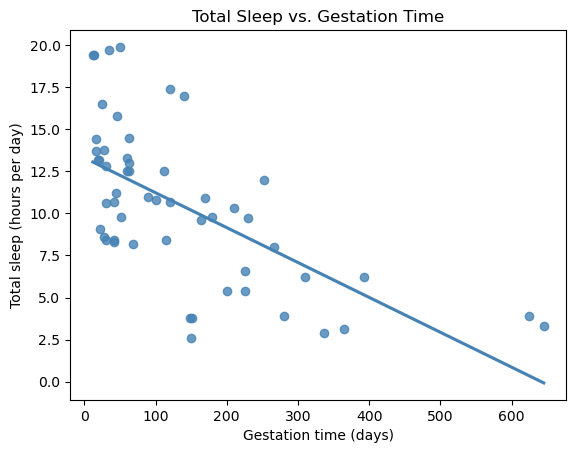

In [23]:
sns.regplot(
    data=gestation_df, x="gestation_time", y="total_sleep",
    color="steelblue", ci=None
)
plt.title("Total Sleep vs. Gestation Time")
plt.xlabel("Gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

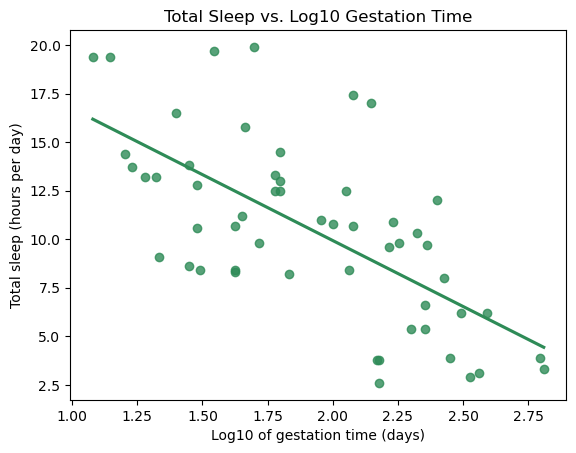

In [24]:
sns.regplot(
    data=gestation_df, x="log10_gestation_time", y="total_sleep",
    color="seagreen", ci=None
)
plt.title("Total Sleep vs. Log10 Gestation Time")
plt.xlabel("Log10 of gestation time (days)")
plt.ylabel("Total sleep (hours per day)")
plt.show()

In [25]:
for predictor in ["gestation_time", "log10_gestation_time"]:
    r = gestation_df[predictor].corr(gestation_df["total_sleep"])
    print(f"{predictor}: r = {r:.4f}, R-squared = {r**2:.4f}")

gestation_time: r = -0.6313, R-squared = 0.3986
log10_gestation_time: r = -0.6637, R-squared = 0.4404


**What changes when gestation is log-transformed? Does the transformation remove the scatter or only improve the straight-line summary modestly?**

Your answer:

Reuse the group-plot and model-comparison approach from Investigation 2, now using `log10_gestation_time` as the predictor and `total_sleep` as the response. Count observations at each rating level in this subset before interpreting the group lines. Examine danger and predation separately, then compare all four additive models on `gestation_df`.

In [26]:
pd.DataFrame({
    "Danger count": gestation_df["danger_index"].value_counts(),
    "Predation count": gestation_df["predation_index"].value_counts()
}).reindex([1, 2, 3, 4, 5]).fillna(0).astype(int)

,Danger count,Predation count
1,16,12
2,12,14
3,10,9
4,9,7
5,7,12


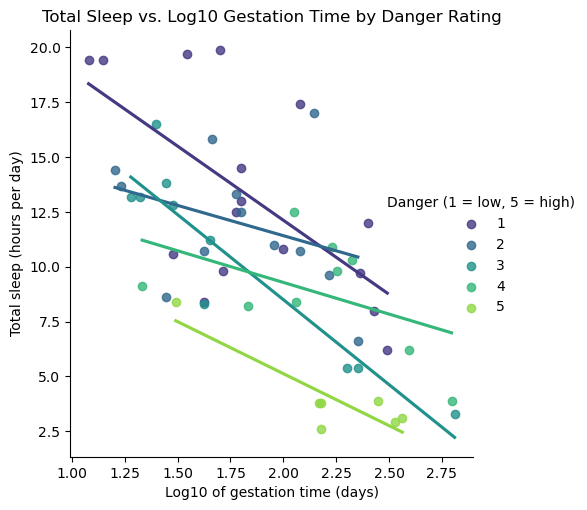

In [27]:
danger_plot = sns.lmplot(
    data=gestation_df, x="log10_gestation_time", y="total_sleep",
    hue="danger_index", hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None
)
danger_plot.set_axis_labels("Log10 of gestation time (days)", "Total sleep (hours per day)")
danger_plot.ax.set_title("Total Sleep vs. Log10 Gestation Time by Danger Rating")
danger_plot.legend.set_title("Danger (1 = low, 5 = high)")
plt.show()

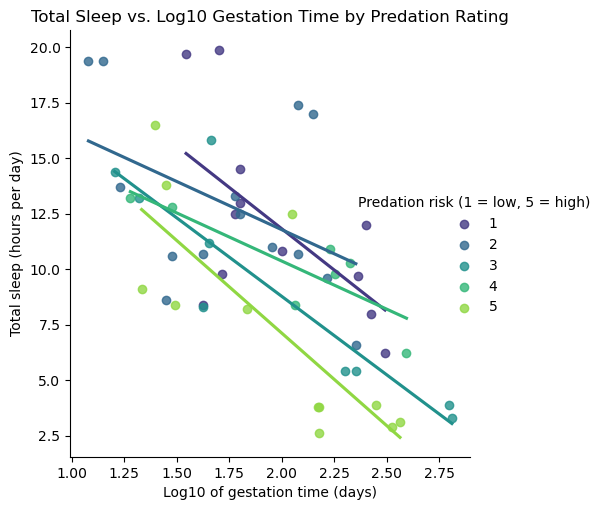

In [28]:
predation_plot = sns.lmplot(
    data=gestation_df, x="log10_gestation_time", y="total_sleep",
    hue="predation_index", hue_order=[1, 2, 3, 4, 5], palette="viridis", ci=None
)
predation_plot.set_axis_labels("Log10 of gestation time (days)", "Total sleep (hours per day)")
predation_plot.ax.set_title("Total Sleep vs. Log10 Gestation Time by Predation Rating")
predation_plot.legend.set_title("Predation risk (1 = low, 5 = high)")
plt.show()

In [29]:
sleep_comparison = pd.DataFrame({
    "Model": list(model_features),
    "R-squared": [
        calculate_r_squared(
            gestation_df, "log10_gestation_time", "total_sleep", features
        )
        for features in model_features.values()
    ]
})

sleep_comparison["Change from baseline"] = (
    sleep_comparison["R-squared"] - sleep_comparison.loc[0, "R-squared"]
)
sleep_comparison.round(4)

,Model,R-squared,Change from baseline
0,Baseline,0.4404,0.0000
1,Baseline + danger,0.6542,0.2137
2,Baseline + predation,0.5917,0.1512
3,Baseline + both,0.6943,0.2538


## Step 4: Check

For the first five records, display gestation time, its logarithm, and `10 ** log10_gestation_time`. Does reversing the logarithm recover the original number of days?

Display the records with the shortest and longest gestation times. Find their points in both plots and compare the recorded sleep hours with their vertical positions. The horizontal positions change when gestation is transformed; the sleep measurements stay the same.

In [30]:
gestation_check = gestation_df[
    ["species", "gestation_time", "log10_gestation_time"]
].head().copy()

gestation_check["recovered_days"] = 10 ** gestation_check["log10_gestation_time"]
gestation_check["matches_original"] = np.isclose(
    gestation_check["recovered_days"], gestation_check["gestation_time"]
)

gestation_check

,species,gestation_time,log10_gestation_time,recovered_days,matches_original
0,African elephant,645.0,2.809560,645.0,True
1,African giant pouched rat,42.0,1.623249,42.0,True
2,Arctic Fox,60.0,1.778151,60.0,True
3,Arctic ground squirrel,25.0,1.397940,25.0,True
4,Asian elephant,624.0,2.795185,624.0,True


In [31]:
gestation_extremes = pd.concat([
    gestation_df.nsmallest(1, "gestation_time"),
    gestation_df.nlargest(1, "gestation_time")
])

gestation_extremes[
    ["species", "gestation_time", "log10_gestation_time", "total_sleep"]
]

,species,gestation_time,log10_gestation_time,total_sleep
38,N. American opossum,12.0,1.079181,19.4
0,African elephant,645.0,2.809560,3.3


**Did reversing the logarithm recover the original gestation times? For the shortest and longest gestation records, do both plots show the recorded total sleep values? Describe what changed between the plots and what stayed the same.**

Your answer Yes, reversing the log gave me the original gestation times for all five records, including 624 days for the Asian elephant. The North American opossum had the shortest gestation at 12 days and slept 19.4 hours per day. The African elephant had the longest gestation at 645 days and slept 3.3 hours per day. Both points showed the same sleep hours in both plots. The horizontal axis changed from days to log10 of days. 

## Step 5: Conclusion

**Research question:** How is total sleep related to gestation time, and do danger and predation add information about sleep after accounting for gestation time? 

**Do mammals with longer gestation times tend to sleep more or less? Does using log gestation make the pattern look straighter? Do danger and predation add information? Support your answers with the plots, correlation, and R-squared values, and compare the results with your prediction.**

Your answer: Mammals with longer gestation times tended to sleep fewer hours. Both plots showed a downward trend, and the log plot looked a little straighter, with plenty of scatter. The correlation went from −0.6313 to −0.6637, and R-squared went from 0.3986 to 0.4404. Adding danger raised R-squared to 0.6542, and adding predation raised it to 0.5917. Using both gave the best fit for the data I used, with an R-squared of 0.6943. I expected them to sleep about the same amount, but the plots showed that mammals with longer gestation times tended to sleep less.

## Step 6: Limitation

**Identify two limitations of the gestation and sleep investigation.**

Your answer: Other factors, like body size, could be related to both gestation time and sleep. This comparison alone can’t tell me whether longer gestation causes mammals to sleep less.

I fit and evaluated the models on the same records. The higher R-squared shows a better fit for those records. I’d need to test on new records to see if the model predicts sleep better.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used ChatGPT to help write and understand the Python code. One suggestion I checked was raising 10 to the logged gestation values. I compared the results with the original days and kept the check because it recovered the values for all five records.

## Submission checklist

- Use the supplied CSV with a relative path.
- Complete the dictionary table and every written response.
- Include a prediction and all six workflow steps for each investigation.
- Include all three sleep comparison plots, two non-dreaming–total group plots, original and log-gestation sleep plots, and two sleep group plots.
- Keep observations consistent within each comparison; report counts and investigate exclusions.
- Interpret correlation and R-squared on the correct scale, using numerical and visual evidence.
- Compare baseline, danger, predation, and combined models without claiming automatic causal or predictive improvement.
- Explain whether the patterns are straight or curved, how the log transformation changes the gestation plot, and what the analyses cannot tell us.
- Complete the AI-use reflection, restart the kernel, and run the notebook in order before submitting.